# QC, clustering & initial analysis of single-cell RNA-seq data

This notebook imports the cellranger output (per sample output; files: barcodes.tsv.gz, features.tsv.gz, matrix.mtx.gz) and creates a scanpy object. The notebook performs quality control, filtering, normalization, clustering and cluster annotation.

# Imports

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import decoupler as dc
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

In [ ]:
sc.settings.verbosity = 3            
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white')

# If notebook is saved in the same folder as the folders containing the barcodes.tsv.gz, features.tsv.gz, matrix.mtx.gz files, this will work, otherwise set the directory accordingly
adata_hfd = sc.read_10x_mtx('HFD') 
adata_lfd = sc.read_10x_mtx('LFD') 


In [ ]:
# specify what the results file should be saved to
results_file = 'hfd_lfd_imq.h5ad'

In [ ]:
adata_hfd.obs['sample'] = 'HFD'
adata_lfd.obs['sample'] = 'LFD'

# merge samples
adata = adata_hfd.concatenate(adata_lfd)

# QC and data preparation

Filter out low quality cells & genes, annotate mitochondrial genes

In [ ]:
# filter out genes that are expressed in fewer than 3 cells and cells that have fewer than 200 transcripts
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

# annotate mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("mt-")

filtered out 4 cells that have less than 200 genes expressed
filtered out 4297 genes that are detected in less than 3 cells


Calculate QC metrics

In [ ]:
sc.pp.calculate_qc_metrics(
    adata, qc_vars=["mt"], percent_top=None, log1p=True, inplace=True
)

Show QC metrics

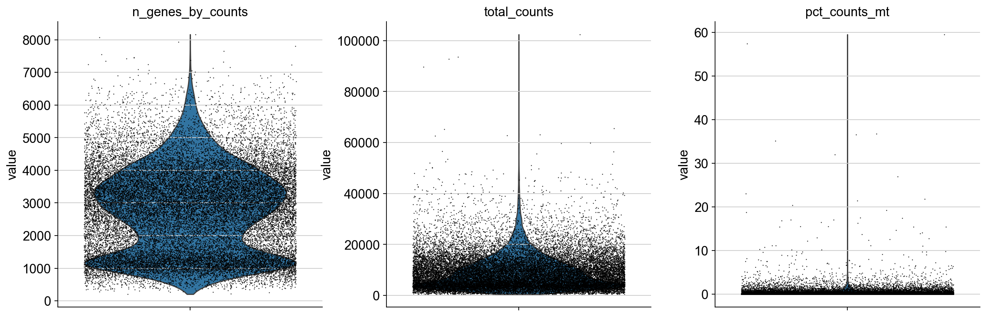

In [ ]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True,
)

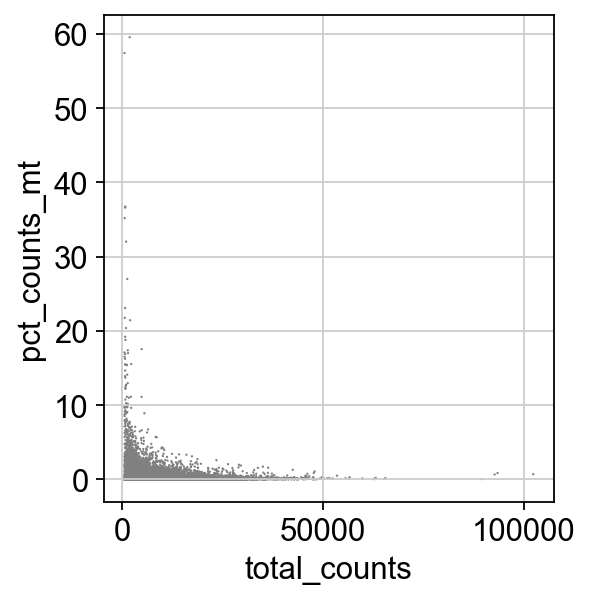

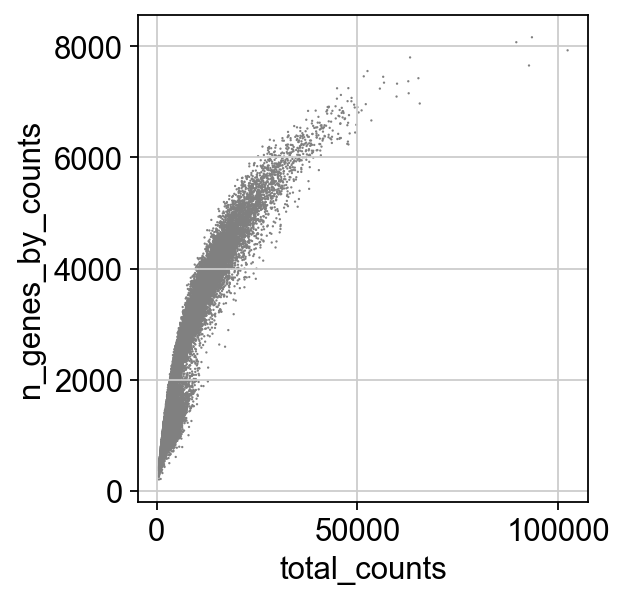

In [ ]:
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts")

Option filtering: remove cells with more than 4000 genes & more than 10% mitochondrial genes (not done in this analysis).

In [ ]:
# adata = adata[adata.obs.n_genes_by_counts < 4000, :]
# adata = adata[adata.obs.pct_counts_mt < 10, :].copy()

Doublet detection using scrublet

In [ ]:
sc.pp.scrublet(adata, batch_key="sample")

Running Scrublet
filtered out 761 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)
normalizing counts per cell
    finished (0:00:00)
normalizing counts per cell
    finished (0:00:00)
Embedding transcriptomes using PCA...
    using data matrix X directly
Automatically set threshold at doublet score = 0.25
Detected doublet rate = 2.3%
Estimated detectable doublet fraction = 36.4%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 6.2%
filtered out 392 genes that are detected in less than 3 cells
normalizing counts per cell
    finished (0:00:00)
extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.v

Normalize to 10,000 reads per cell

In [ ]:
sc.pp.normalize_total(adata, target_sum=1e4)

normalizing counts per cell
    finished (0:00:00)


Logarithmize the data

In [ ]:
sc.pp.log1p(adata)

Calculate highly variable genes

In [ ]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


Plot highly variable genes

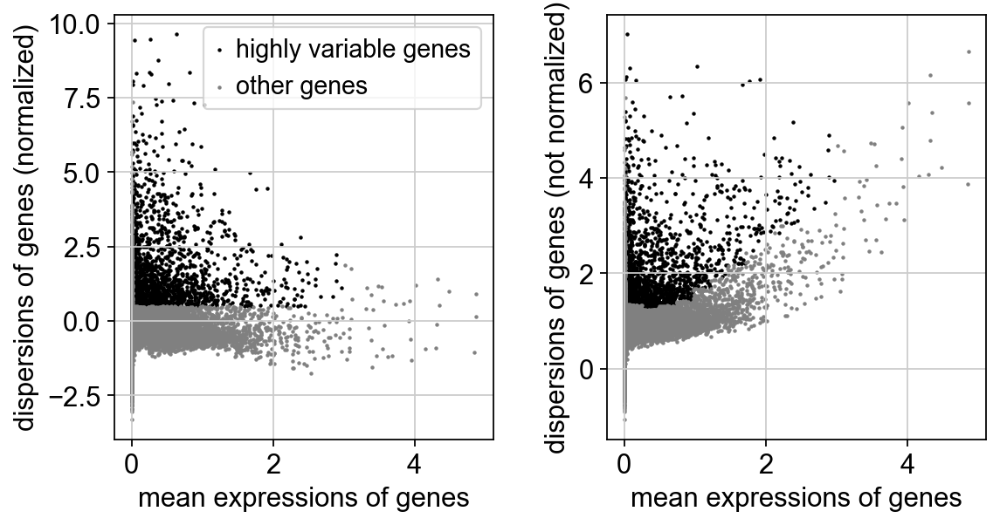

In [ ]:
sc.pl.highly_variable_genes(adata)

Plot top 20 genes with the highest expression

normalizing counts per cell
    finished (0:00:00)


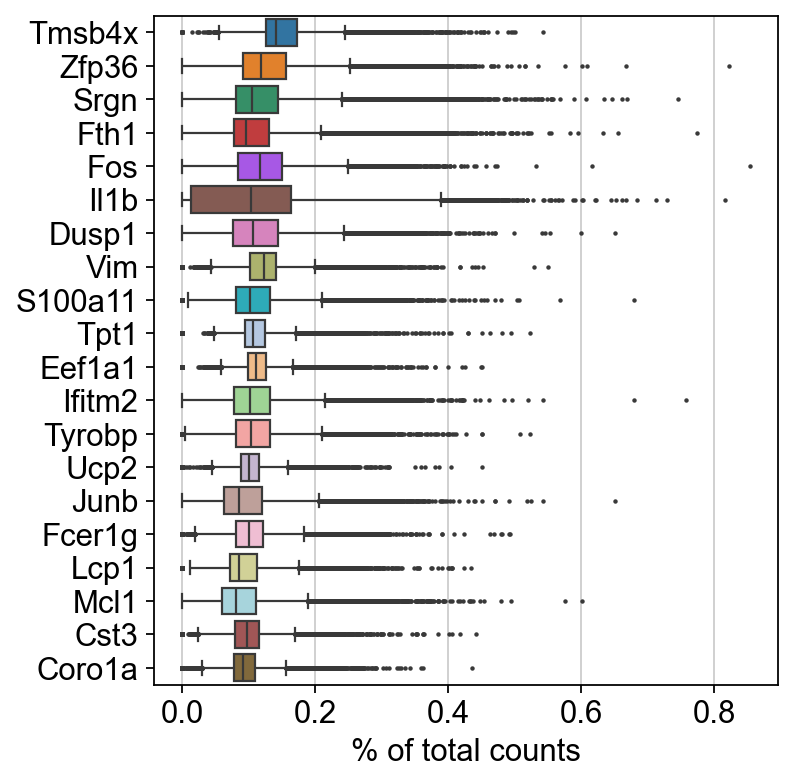

In [ ]:
sc.pl.highest_expr_genes(adata, n_top=20, )

# Clustering

Calculate PCA, UMAP and Leiden clusters

In [ ]:
sc.tl.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, flavor="igraph", n_iterations=2)

computing PCA
    with n_comps=50
    finished (0:00:02)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:11)
running Leiden clustering
    finished: found 29 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


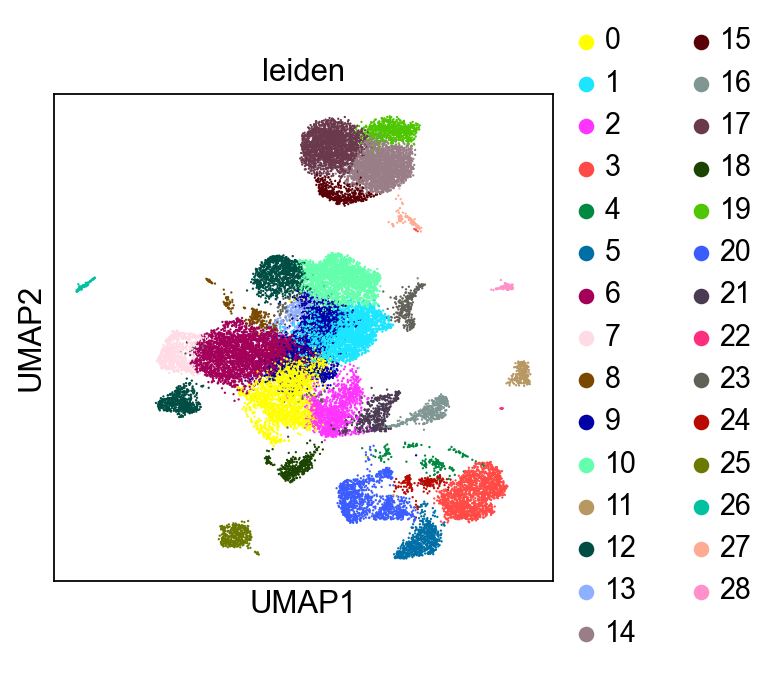

In [ ]:
sc.pl.umap(adata, color=["leiden"])

Check QC metrics on clusters

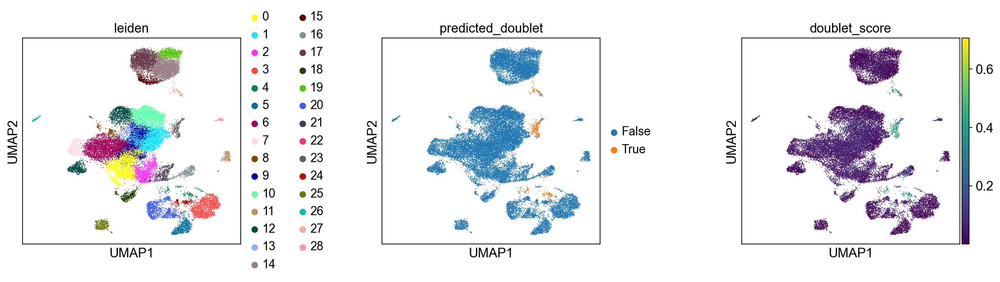

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "predicted_doublet", "doublet_score"],
    wspace=0.5,
    size=3,
)

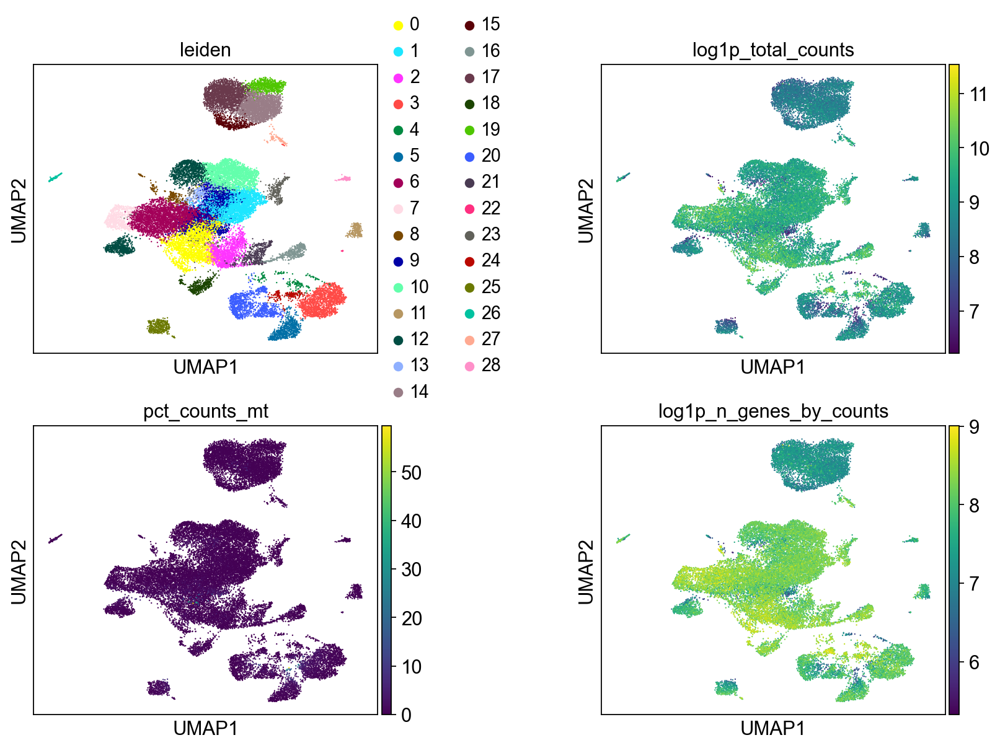

In [ ]:
sc.pl.umap(
    adata,
    color=["leiden", "log1p_total_counts", "pct_counts_mt", "log1p_n_genes_by_counts"],
    wspace=0.5,
    ncols=2,
)

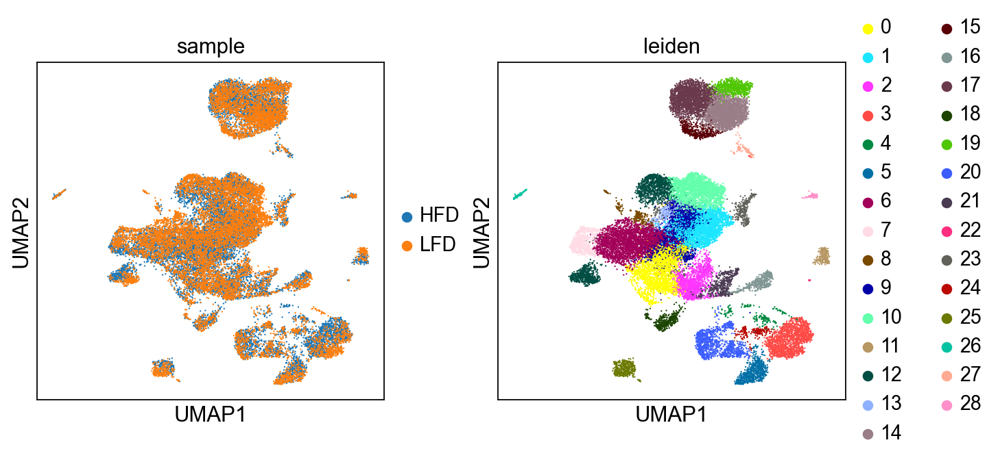

In [ ]:
sc.pl.umap(adata, color=['sample', 'leiden'])

Remove doublets

In [ ]:
adata = adata[adata.obs.predicted_doublet == False, :]

Save results file

In [ ]:
adata.write(results_file)

### Conclusions: 
1. We can see that there are doublets in the data, which should be removed.
2. The default leiden clustering resolution is probably too high, as we can see that there are many clusters.
3. Not many cells express high levels of mitochondrial genes, so we leave them in for now.

# Re-clustering after QC

A resolution of 1 produced 28 clusters, which is likely too many for a high-level analysis. 0.5 produced 14 clusters, which is closer to what we would expect. This can be adjusted as needed.

In [ ]:
# # import h5ad file if starting from here
# adata = sc.read_h5ad(results_file)

Recluster with a lower resolution.

running Leiden clustering
    finished: found 15 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


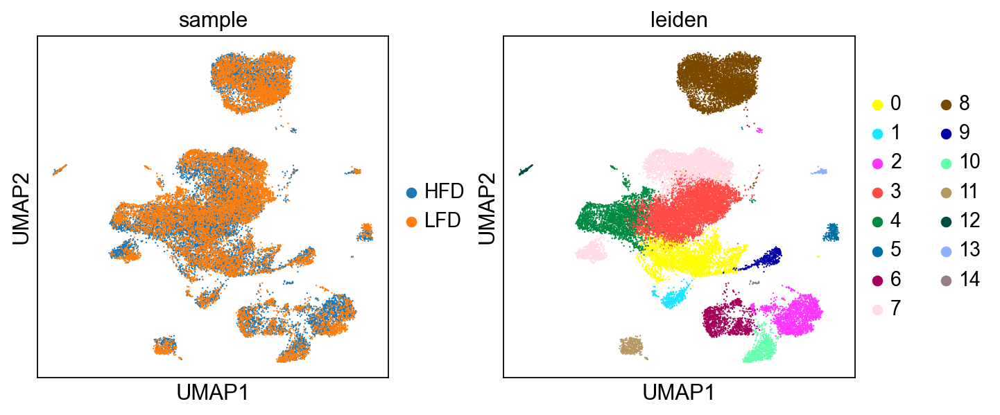

In [ ]:
sc.tl.leiden(
    adata, resolution=0.5, flavor="igraph"
)
sc.pl.umap(adata, color=['sample', 'leiden'])

Obtain cluster-specific differentially expressed genes for cell type annotation

In [ ]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:18)


Plot top 5 genes per cluster.

    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_leiden']`


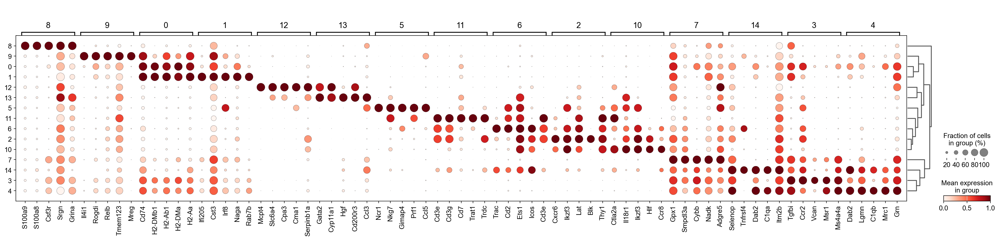

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata, groupby="leiden", standard_scale="var", n_genes=5
)

This dotplot displays the top 5 expressed genes in each cluster. For some clusters, this is enough to annotate the cluster (for example cluster 6 that expresses Trac and Cd3e), but for others, we need to do some more in-depth analysis of the top expressed genes.

# Decoupler for automated cell type annotation

Using automatic cell type annotation can help with annotation of clusters. This is never perfect, but can, together with knowledge of our dataset and key markers, help with annotation. 

Get data from PangaloDB (public database)

In [ ]:
markers = dc.get_resource(
    name='PanglaoDB',
    organism='mouse',
    license='academic'
)

/Users/scc/miniconda3/envs/scrnaseq/lib/python3.11/site-packages/liana/resource/_orthology.py:199: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.


Clean up dataset to include mouse canonical markers and remove duplicated entries.

In [ ]:
# Filter by canonical_marker and mouse
markers = markers[markers['mouse'].astype(bool) & markers['canonical_marker'].astype(bool) & (markers['mouse_sensitivity'].astype(float) > 0.5)]

# Remove duplicated entries
markers = markers[~markers.duplicated(['cell_type', 'genesymbol'])]

Run ORA (Over Representation Analysis) to find enriched cell types in the clusters. 

In [ ]:
dc.run_ora(
    mat=adata,
    net=markers,
    source='cell_type',
    target='genesymbol',
    min_n=3,
    verbose=True,
    use_raw=False
)

Running ora on mat with 27157 samples and 14773 targets for 95 sources.


  0%|          | 0/27157 [00:00<?, ?it/s]

Extract obtained enrichment scores from adata

In [ ]:
acts = dc.get_acts(adata, obsm_key='ora_estimate')

acts_v = acts.X.ravel()
max_e = np.nanmax(acts_v[np.isfinite(acts_v)])
acts.X[~np.isfinite(acts.X)] = max_e

Check that it worked as expected (each cell gets a score for each cell type)

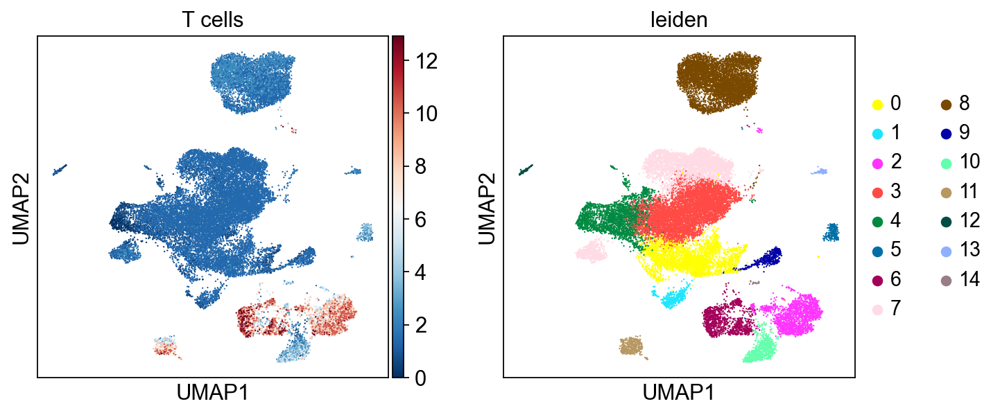

In [ ]:
sc.pl.umap(acts, color=['T cells', 'leiden'], cmap='RdBu_r')


Identify the top marker cell types per leiden cluster

In [ ]:
df = dc.rank_sources_groups(acts, groupby='leiden', reference='rest', method='t-test_overestim_var')

Calculate & plot the top 3 predicted cell types per leiden cluster

In [ ]:
n_ctypes = 3
ctypes_dict = df.groupby('group').head(n_ctypes).groupby('group')['names'].apply(lambda x: list(x)).to_dict()

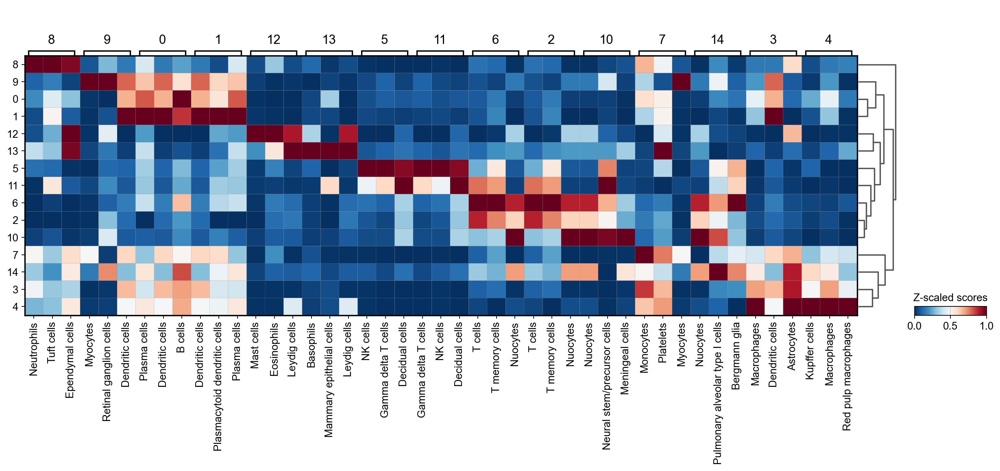

In [ ]:
sc.pl.matrixplot(acts, ctypes_dict, 'leiden', dendrogram=True, standard_scale='var',
                 colorbar_title='Z-scaled scores', cmap='RdBu_r')

# Combined cell type annotation

This, together with the differentiall expressed genes will help us annotate the clusters. This is a first draft of clusters: 

Clusters
0 B cell / DCs <br>
1 DCs / B cells <br>
2 gdT cells <br>
3 Macrophages / DCs <br>
4 Macrophages<br>
5 NK / gdT cells<br>
6 CD4 T cells (incl. Tregs)<br>
7 Monocytes<br>
8 Neutrophils<br>
9 DC<br>
10 ?<br>
11 gdT cells<br>
12 Mast cells / eosinophils<br>
13 Basophils<br>
14 ILC2<br>

There are still a few clusters where the annotation isn't 100%, so we will look at them in more detail and annotate them using known markers. CellMarker 2.0 is a great resource for that: http://www.bio-bigdata.center/

Clusters 0 and 1 both annotated as either DCs or B cells: 

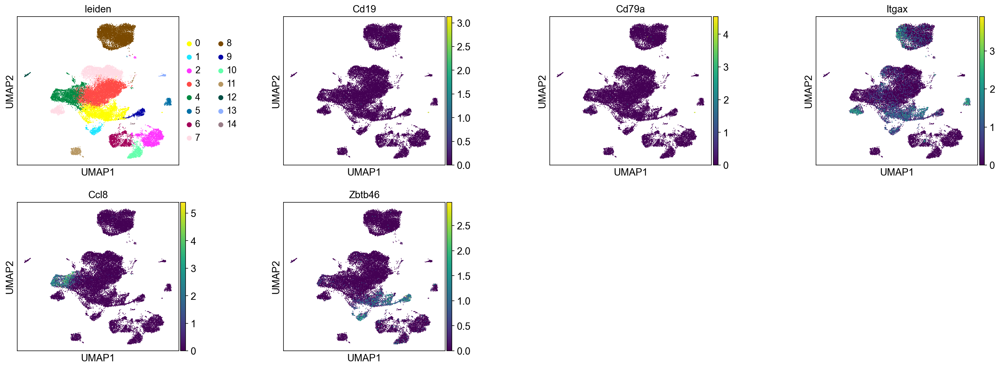

In [ ]:
sc.pl.umap(adata, color=['leiden', 'Cd19', 'Cd79a', 'Itgax', 'Ccl8', 'Zbtb46'], wspace=0.5)

Both cluster 0 and 1 express Itgax (CD11c - can be expressed by B cells) and Zbtb46 (expressed in cDCs only). Neither of the B cell markers are expressed by the clusters (except the very small subcluster on the right). So I think both of them are DCs. 

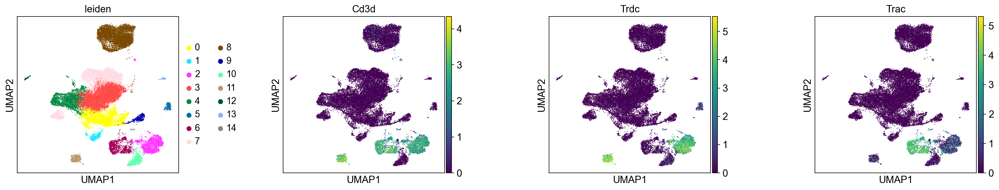

In [ ]:
sc.pl.umap(adata, color=['leiden', 'Cd3d', 'Trdc', 'Trac'], wspace=0.5)

Cluster 2 and 11 express high levels of Trdc and while some Trac transcript is expressed, I would annotate them as gdT cells for now.

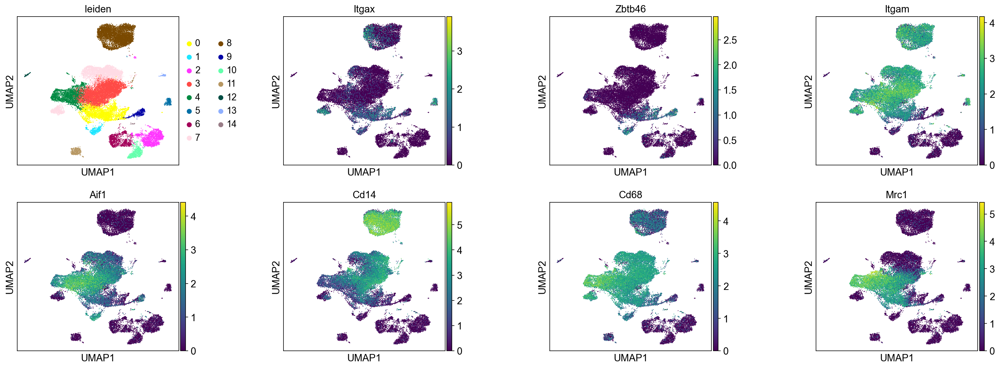

In [ ]:
sc.pl.umap(adata, color=['leiden', 'Itgax', 'Zbtb46', 'Itgam', 'Aif1', 'Cd14', 'Cd68', 'Mrc1'], wspace=0.5)

Cluster 3 clearly looks like macrophages

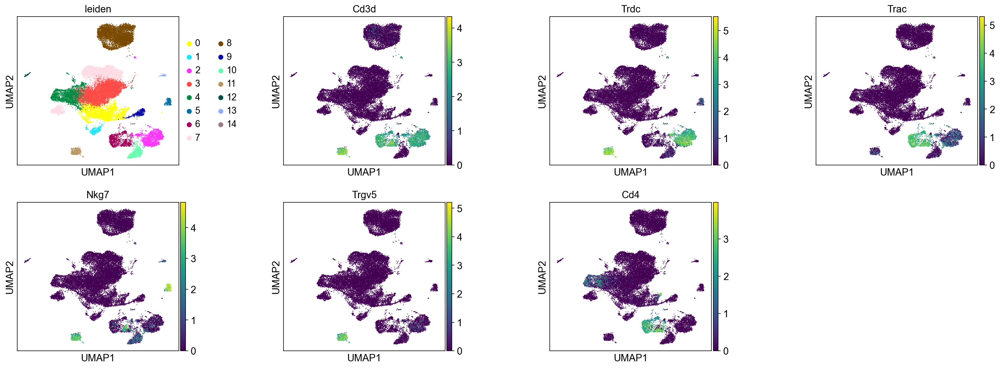

In [ ]:
sc.pl.umap(adata, color=['leiden', 'Cd3d', 'Trdc', 'Trac', 'Nkg7', 'Trgv5', 'Cd4'], wspace=0.5)

Cluster 5 was annotated as NK cells or gdT cells, I think they are mostly NK cells. 

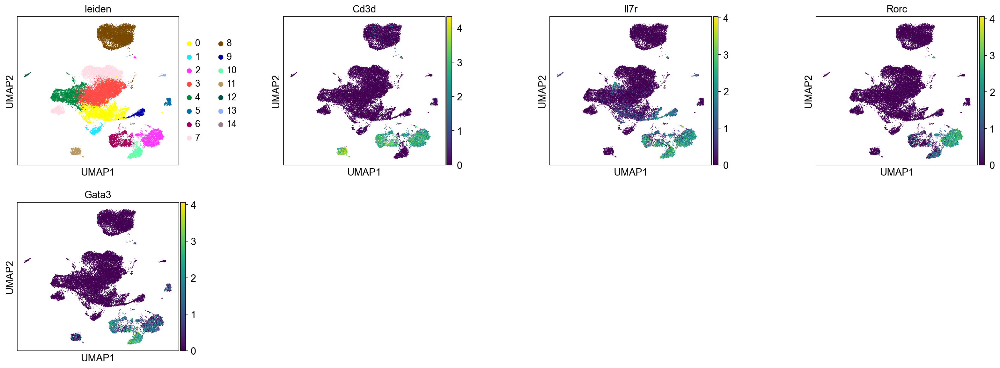

In [ ]:
sc.pl.umap(adata, color=['leiden', 'Cd3d', 'Il7r', 'Rorc', 'Gata3'], wspace=0.5)

In [ ]:
cluster2annotation = {
     '0': 'DC 1',
     '1': 'DC 2',
     '2': 'gdT/Th17 cells',
     '3': 'Macrophages 1',
     '4': 'Macrophages 2',
     '5': 'NK cells',
     '6': 'CD4 T cells',
     '7': 'Monocytes',
     '8': 'Neutrophils',
     '9': 'DC 3',
     '10': 'ILC 2 1',
     '11': 'DETCs',
     '12': 'Mast cells / eosinophils',
     '13': 'Basophils',
     '14': 'ILC2 2'
}

Add new cell type annotation

In [ ]:
adata.obs['cell type'] = adata.obs['leiden'].map(cluster2annotation).astype('category')

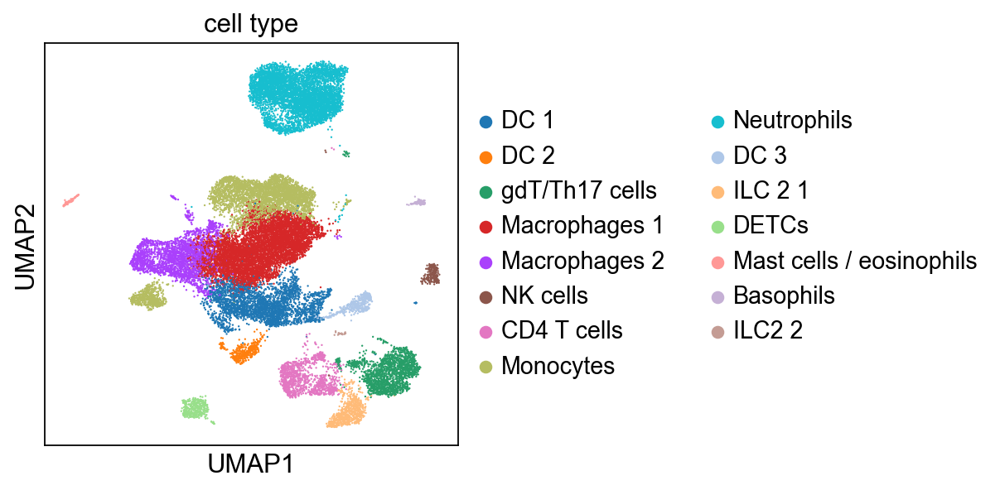

In [ ]:
sc.pl.umap(adata, color = 'cell type', wspace=0.5)

CD4 T cells and monocytes are made up of two distinct clusters each. In the CD4 T cell subset, one is the cluster of Tregs and the other one probably proliferating T cells. For the macrophages, Macroophages 2 seems to express lower levels of Nlrp3.

Create new adata for Monocytes only to have a better look at those specific clusters.

In [ ]:
monocytes = adata[adata.obs['cell type'] == 'Monocytes'].copy()

running Leiden clustering


/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_45173/4140293629.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


    finished: found 3 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


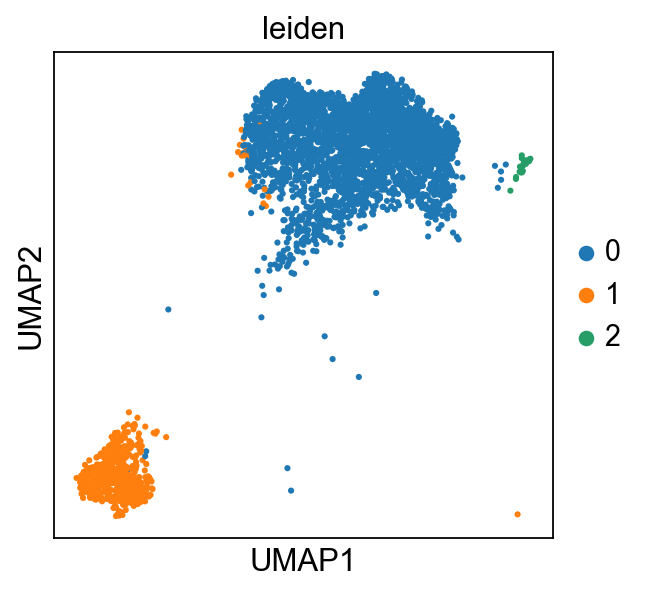

In [ ]:
sc.tl.leiden(monocytes, resolution=0.075)
sc.pl.umap(monocytes, color = 'leiden')

In [ ]:
monocytes.obs['monocyte_subcluster'] = monocytes.obs['leiden'].map({'0': 'Monocytes 1', '1': 'Monocytes 2', '2': 'Monocytes 1'})

Same for CD4s

In [ ]:
cd4 = adata[adata.obs['cell type'] == 'CD4 T cells'].copy()

running Leiden clustering
    finished: found 3 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


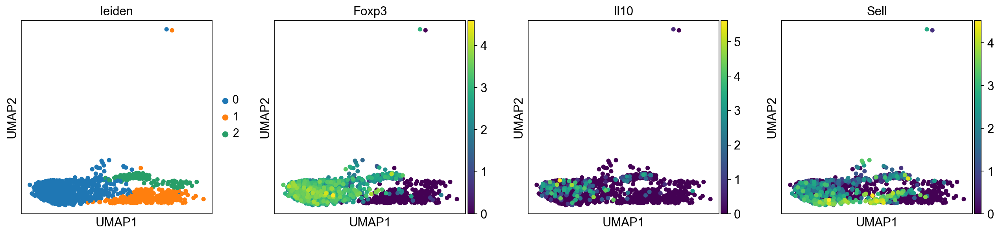

In [ ]:
sc.tl.leiden(cd4, resolution=0.075)
sc.pl.umap(cd4, color = ['leiden', 'Foxp3', 'Il10', 'Sell'])

In [ ]:
cd4.obs['cd4_subcluster'] = cd4.obs['leiden'].map({'0': 'Treg', '1': 'CD4 T cells', '2': 'CD4 T cells'})

Add new categories

In [ ]:
new_cats = pd.Index(['Monocytes 1', 'Monocytes 2', 'Treg', 'CD4 T cells', 'CD4 T cells'])
adata.obs['cell type'] = adata.obs['cell type'].cat.add_categories(new_cats.difference(adata.obs['cell type'].cat.categories))

mask = (adata.obs_names.isin(monocytes.obs_names)) & (adata.obs['cell type'] == 'Monocytes')
adata.obs.loc[mask, 'cell type'] = monocytes.obs['monocyte_subcluster'].reindex(adata.obs_names[mask]).values

mask = (adata.obs_names.isin(cd4.obs_names)) & (adata.obs['cell type'] == 'CD4 T cells')
adata.obs.loc[mask, 'cell type'] = cd4.obs['cd4_subcluster'].reindex(adata.obs_names[mask]).values


adata.obs['cell type'] = adata.obs['cell type'].cat.remove_unused_categories()

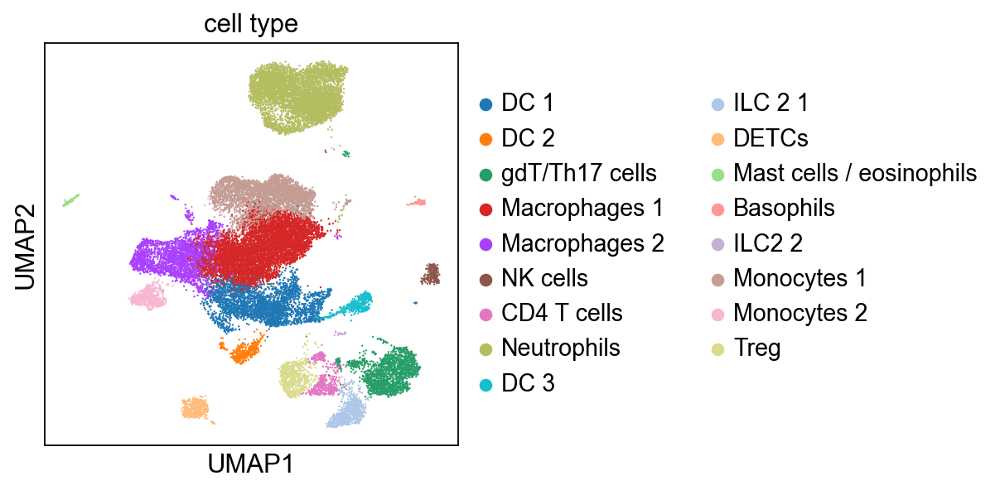

In [ ]:
sc.pl.umap(adata, color=['cell type'])

Save the annotated adata object

In [ ]:
adata.write(results_file)

# Further refining cell subsets

Import h5ad file if starting from here

In [ ]:
adata = sc.read_h5ad(results_file)

There are still a few cell types that span across several clusters. To determine the differences between these and further annotate them, we check the differentially expressed genes between the clusters. 

## CD4

In [ ]:
cd4_types = ['CD4 T cells', 'Treg', 'gdT/Th17 cells']
adata_cd4 = adata[adata.obs['cell type'].isin(cd4_types)].copy()
sc.tl.rank_genes_groups(
    adata_cd4,
    groupby='cell type',
)


ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_cell type']`


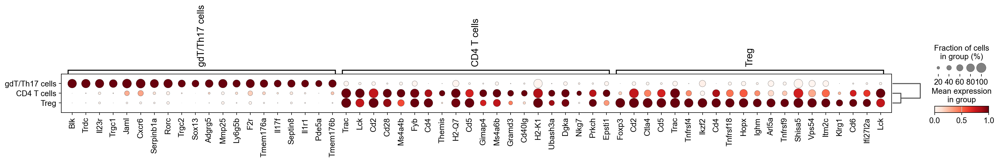

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata_cd4,
    groupby='cell type',
    standard_scale='var',
    n_genes=20
)


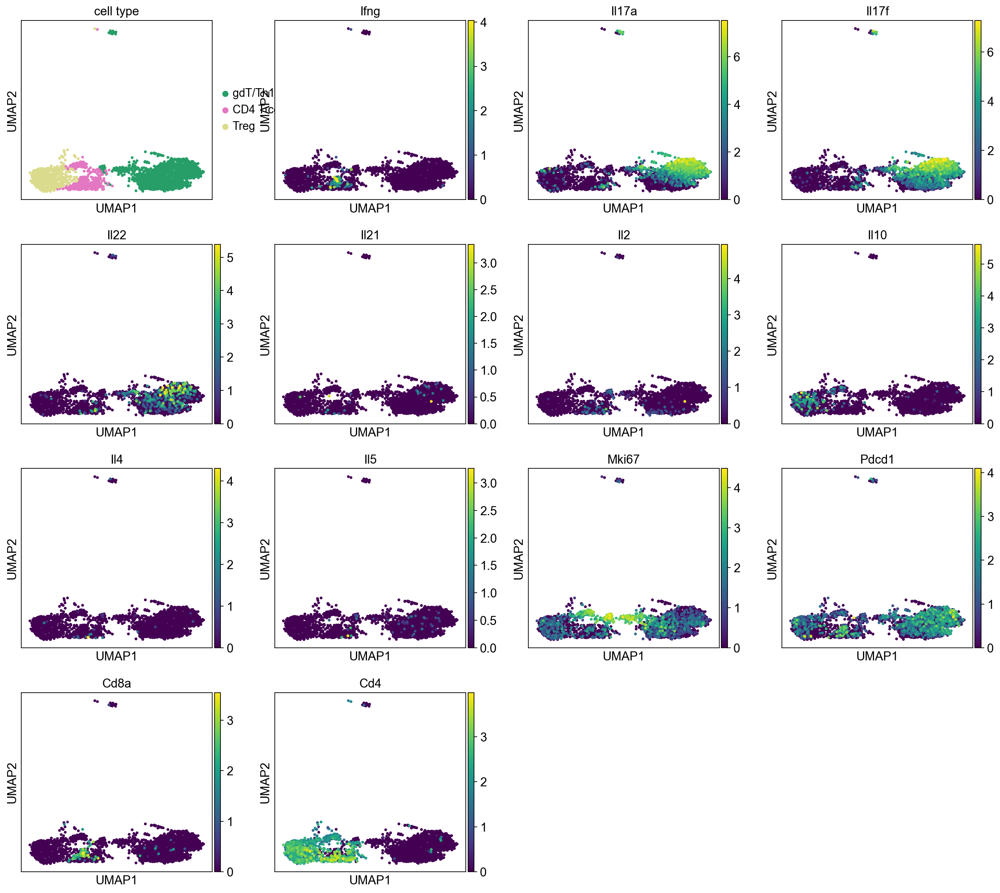

In [ ]:
sc.pl.umap(adata_cd4, color=['cell type', 'Ifng', 'Il17a', 'Il17f', 'Il22', 'Il21', 'Il2', 'Il10', 'Il4', 'Il5', 'Mki67', 'Pdcd1', 'Cd8a', 'Cd4'])

### DCs

In [ ]:
dc_types = ['DC 1', 'DC 2', 'DC 3']
adata_dc = adata[adata.obs['cell type'].isin(dc_types)].copy()

In [ ]:
sc.tl.rank_genes_groups(
    adata_dc,
    groupby='cell type',
)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


    using 'X_pca' with n_pcs = 50
Storing dendrogram info using `.uns['dendrogram_cell type']`


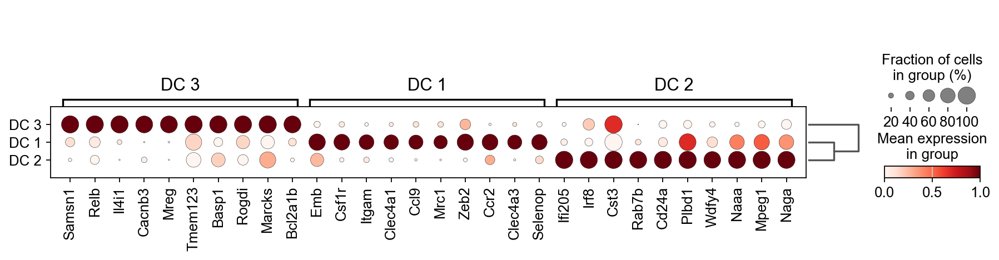

In [ ]:
sc.pl.rank_genes_groups_dotplot(
    adata_dc,
    groupby='cell type',
    standard_scale='var',
    n_genes=10
)


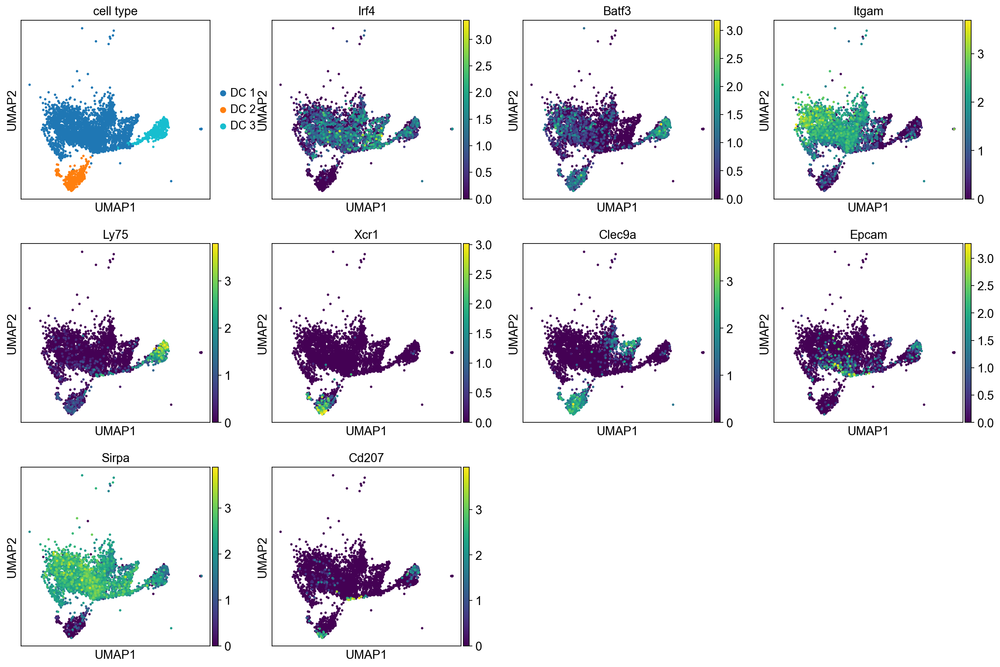

In [ ]:
sc.pl.umap(adata_dc, color=['cell type', 'Irf4', 'Batf3', 'Itgam', 'Ly75', 'Xcr1', 'Clec9a', 'Epcam', 'Sirpa', 'Cd207'])

DC 1 = cDC2 (Itgam)
DC 3 = Langerhans cells/dermal DCs (high Ly75 expression)
DC 2 = cDC1 (low levels of Ly75, high Xcr1 and Clec9a)


## Macrophages

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


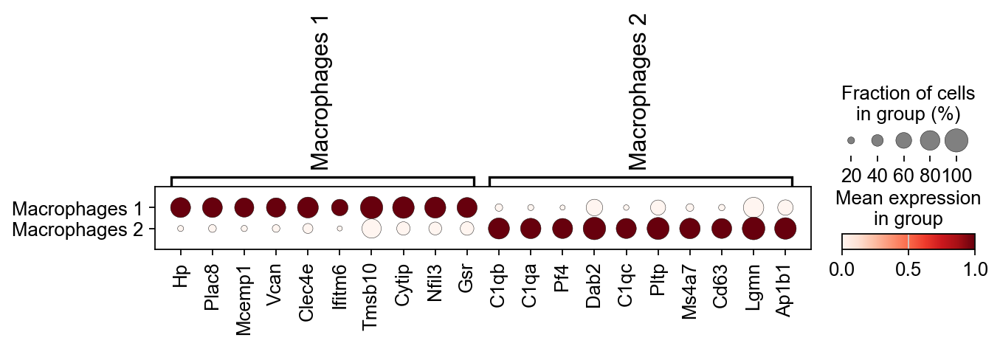

In [ ]:
macrophage_types = ['Macrophages 1', 'Macrophages 2']
adata_macrophages = adata[adata.obs['cell type'].isin(macrophage_types)].copy()

sc.tl.rank_genes_groups(
    adata_macrophages,
    groupby='cell type',
)

sc.pl.rank_genes_groups_dotplot(
    adata_macrophages,
    groupby='cell type',
    standard_scale='var',
    n_genes=10
)


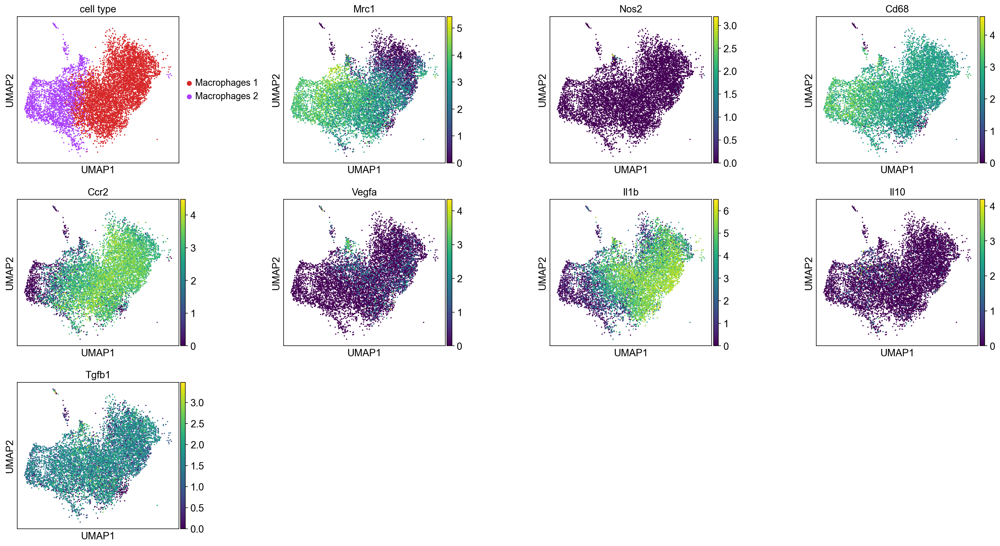

In [ ]:
sc.pl.umap(adata_macrophages, color=['cell type', 'Mrc1', 'Nos2', 'Cd68', 'Ccr2', 'Vegfa', 'Il1b', 'Il10', 'Tgfb1'], wspace=0.5)

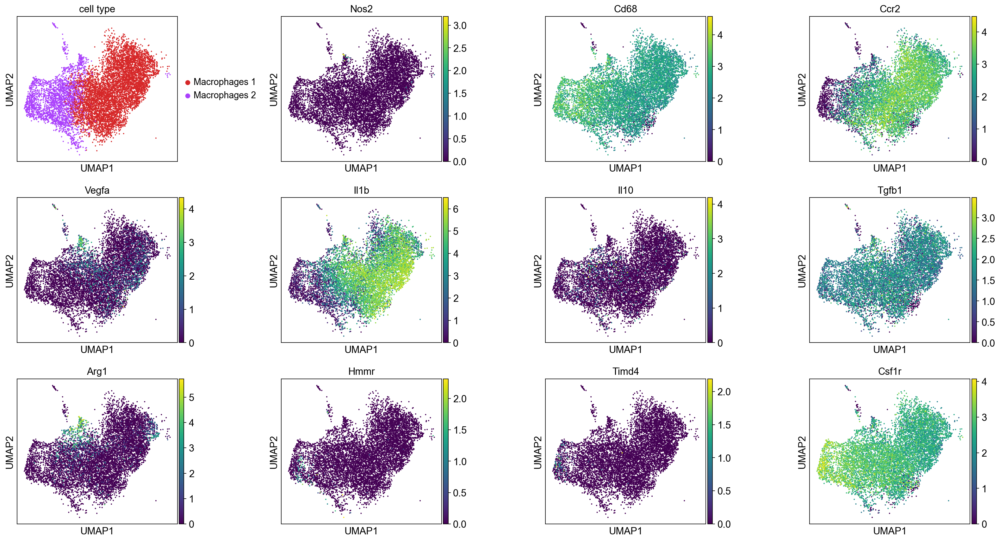

In [ ]:
sc.pl.umap(adata_macrophages, color=['cell type', 'Nos2', 'Cd68', 'Ccr2', 'Vegfa', 'Il1b', 'Il10', 'Tgfb1', 'Arg1', 'Hmmr', 'Timd4', 'Csf1r'], wspace=0.5)

Macrophages 1: M1, Macrophages 2: M2

## ILC2s

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


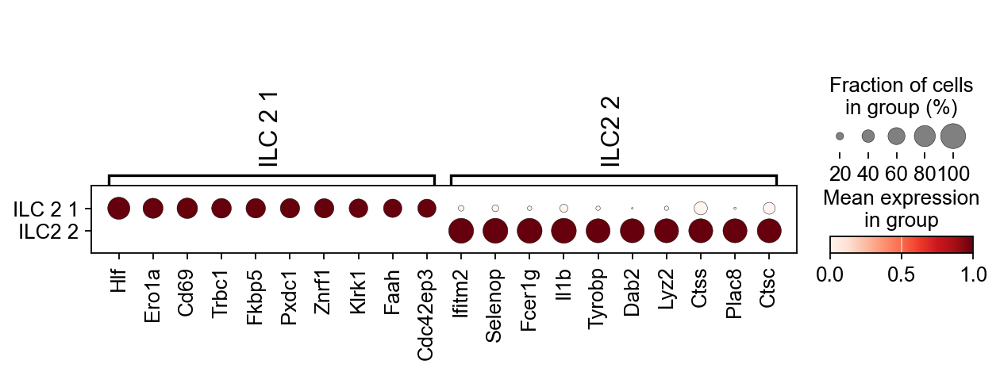

In [ ]:
ilc2_types = ['ILC 2 1', 'ILC2 2']
adata_ilc2 = adata[adata.obs['cell type'].isin(ilc2_types)].copy()

sc.tl.rank_genes_groups(
    adata_ilc2,
    groupby='cell type',
)

sc.pl.rank_genes_groups_dotplot(
    adata_ilc2,
    groupby='cell type',
    standard_scale='var',
    n_genes=10
)

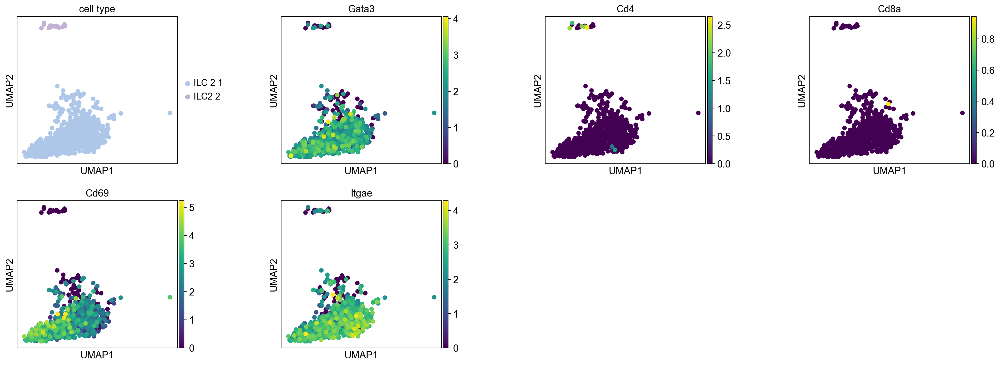

In [ ]:
sc.pl.umap(adata_ilc2, color=['cell type', 'Gata3', 'Cd4', 'Cd8a', 'Cd69', 'Itgae'], wspace=0.5)

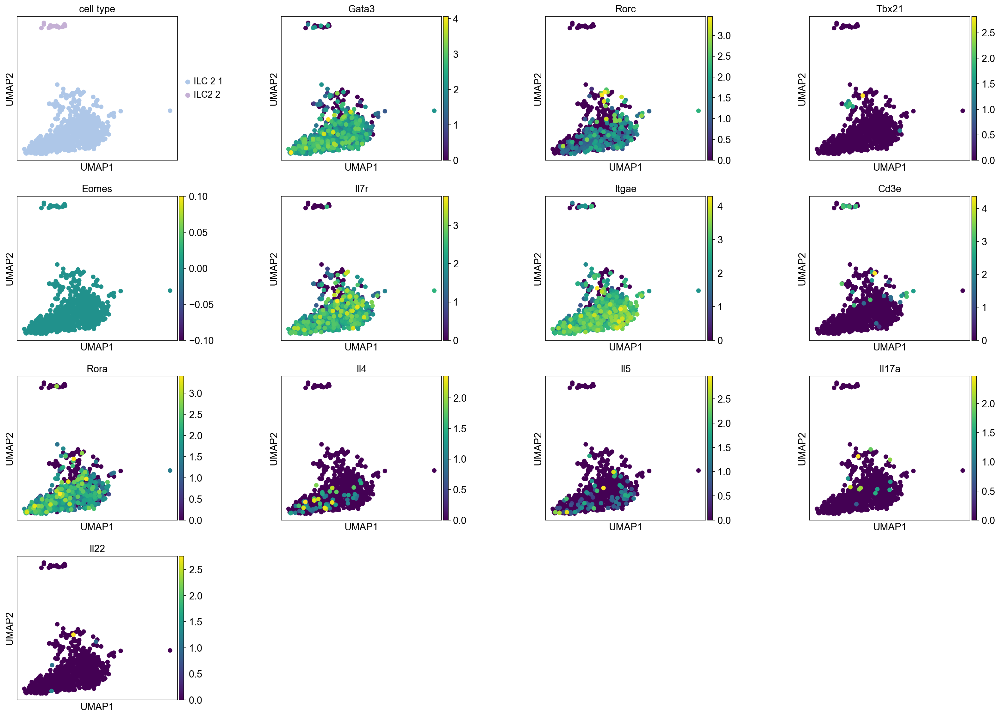

In [ ]:
sc.pl.umap(adata_ilc2, color=['cell type', 'Gata3', 'Rorc', 'Tbx21', 'Eomes', 'Il7r', 'Itgae', 'Cd3e', 'Rora', 'Il4', 'Il5', 'Il17a', 'Il22'], wspace=0.5)

Cluster 2 appears to be T cells (expressing Cd3e, probably Th2 based on Gata3 expression?)
Not 100% sure what the other cluster is. There are definitely ILC2s in there (Gata3, Il4, Il5 expression), but maybe also ILC3s (Rorc)

ranking genes
    finished: added to `.uns['rank_genes_groups']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


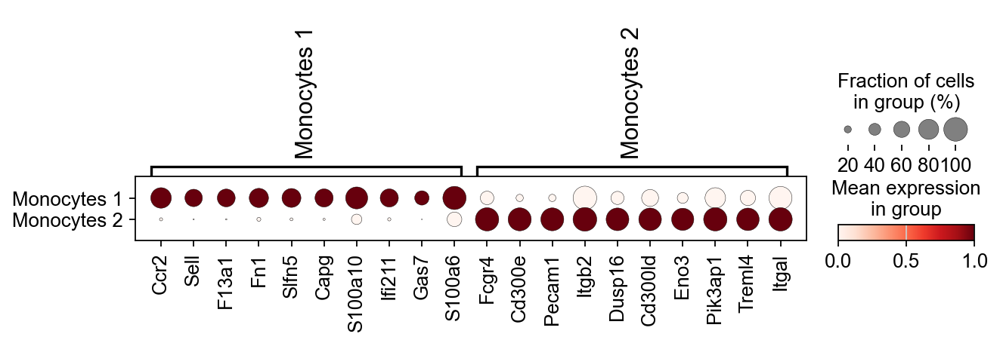

In [ ]:
monocyte_types = ['Monocytes 1', 'Monocytes 2']
adata_monocytes = adata[adata.obs['cell type'].isin(monocyte_types)].copy()

sc.tl.rank_genes_groups(
    adata_monocytes,
    groupby='cell type',
)

sc.pl.rank_genes_groups_dotplot(
    adata_monocytes,
    groupby='cell type',
    standard_scale='var',
    n_genes=10
)

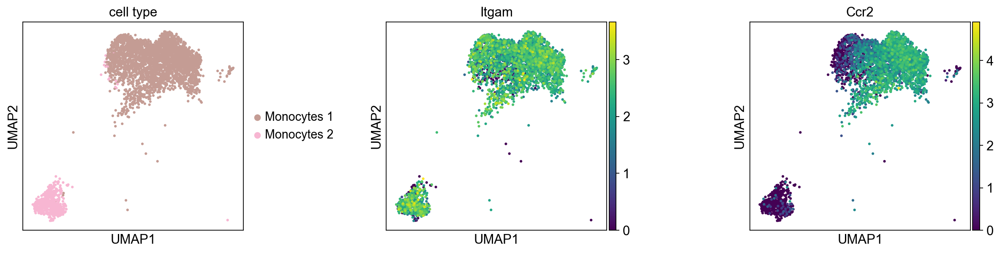

In [ ]:
sc.pl.umap(adata_monocytes, color=['cell type', 'Itgam', 'Ccr2'], wspace=0.5)

Monocyte 1 = Classical monocyte (based on CCR2 expression)

## Renaming cell types - final cell types

In [ ]:
adata.obs['cell type'] = adata.obs['cell type'].replace({
    'ILC2 2': 'Th2',
    'ILC 2 1': 'ILCs',
    'DC 1': 'cDC2',
    'DC 2': 'cDC1',
    'DC 3': 'Langerhans cells/dDCs',
    'Macrophages 1': 'M1',
    'Macrophages 2': 'M2',
    'Monocytes 1': 'Classical monocyte',
    'Monocytes 2': 'Non-classical monocyte'
})

/var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T/ipykernel_45176/2690305932.py:1: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.


Figure 3h

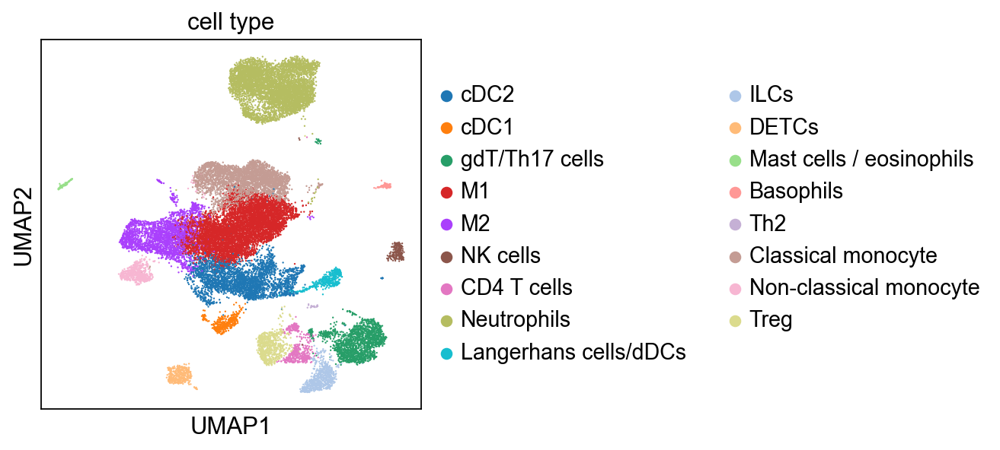

In [ ]:
sc.pl.umap(adata, color=['cell type'])

In [ ]:
adata.write(results_file)

# Plotting

Import h5ad file if starting from here

In [7]:
adata = sc.read_h5ad(results_file)

Plot specific markers of interest - Figure 3i & j

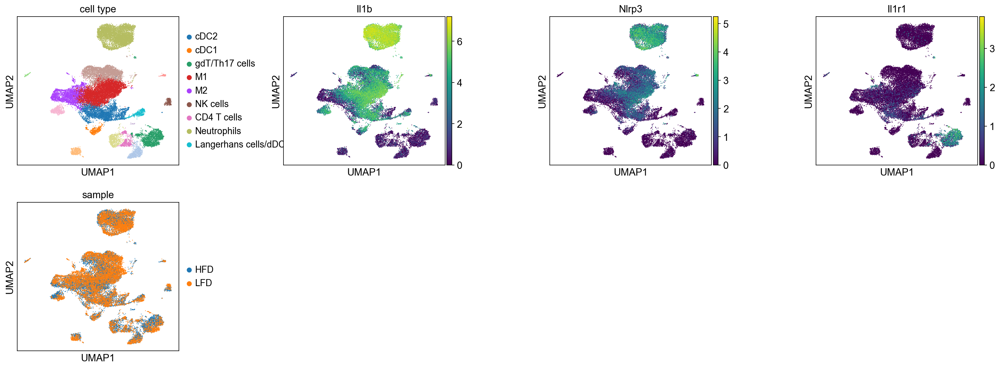

In [ ]:
sc.pl.umap(adata, color = ['cell type', 'Il1b', 'Nlrp3', 'Il1r1', 'sample'], wspace=0.5)

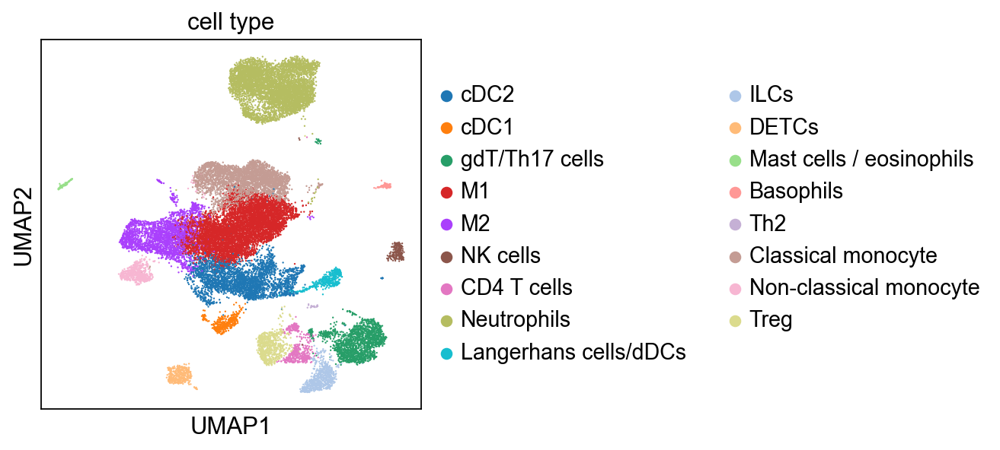

In [ ]:
sc.pl.umap(adata, color = ['cell type'])

Extended Data Figure 5g


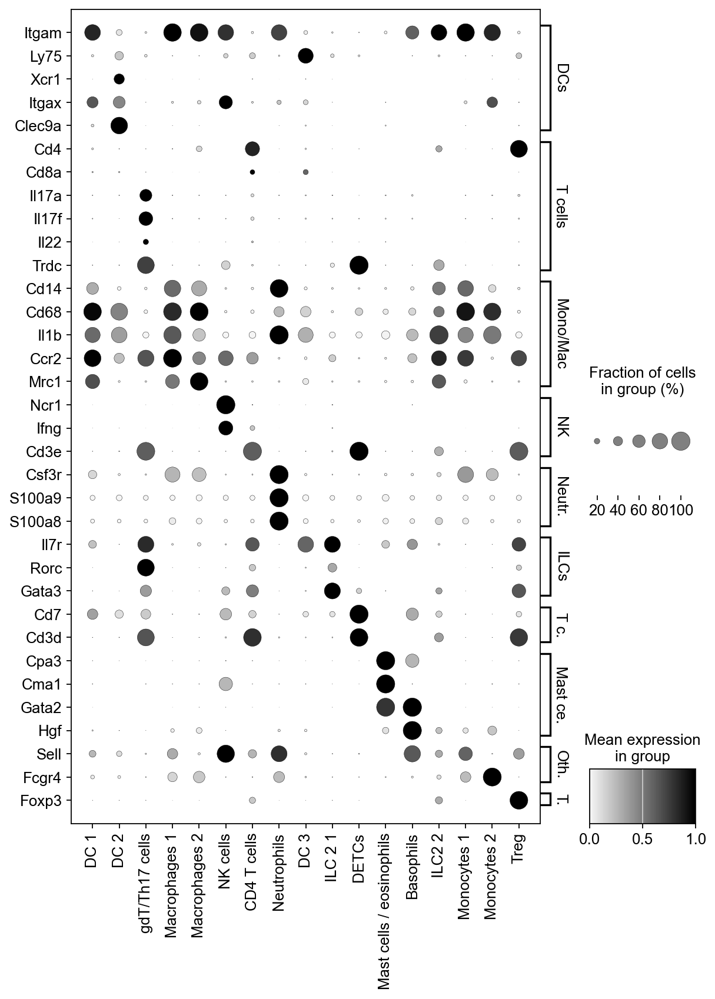

In [11]:
colors = ['whitesmoke', 'black']
n_bins = 100
cmap = LinearSegmentedColormap.from_list('custom_gray', colors, N=n_bins)

marker_genes = {
    'DCs': ['Itgam', 'Ly75', 'Xcr1', 'Itgax', 'Clec9a'],
    'T cells': ['Cd4', 'Cd8a', 'Il17a', 'Il17f', 'Il22', 'Trdc'],
    'Mono/Mac': ['Cd14', 'Cd68', 'Il1b', 'Ccr2', 'Mrc1'],
    'NK': ['Ncr1', 'Ifng', 'Cd3e'],
    'Neutrophils': ['Csf3r', 'S100a9', 'S100a8'],
    'ILCs': ['Il7r', 'Rorc', 'Gata3'],
    'T cell markers': ['Cd7', 'Cd3d'],
    'Mast cells': ['Cpa3', 'Cma1', 'Gata2', 'Hgf'],
    'Other': ['Sell', 'Fcgr4'],
    'Tregs': ['Foxp3'],
}

sc.pl.dotplot(
    adata,
    var_names=marker_genes,
    groupby='cell type',
    use_raw=False,
    cmap=cmap,
    standard_scale='var',
    swap_axes=True,
    figsize=(8.5, 11),
    save='_genes_of_interest_bulk.svg',
)

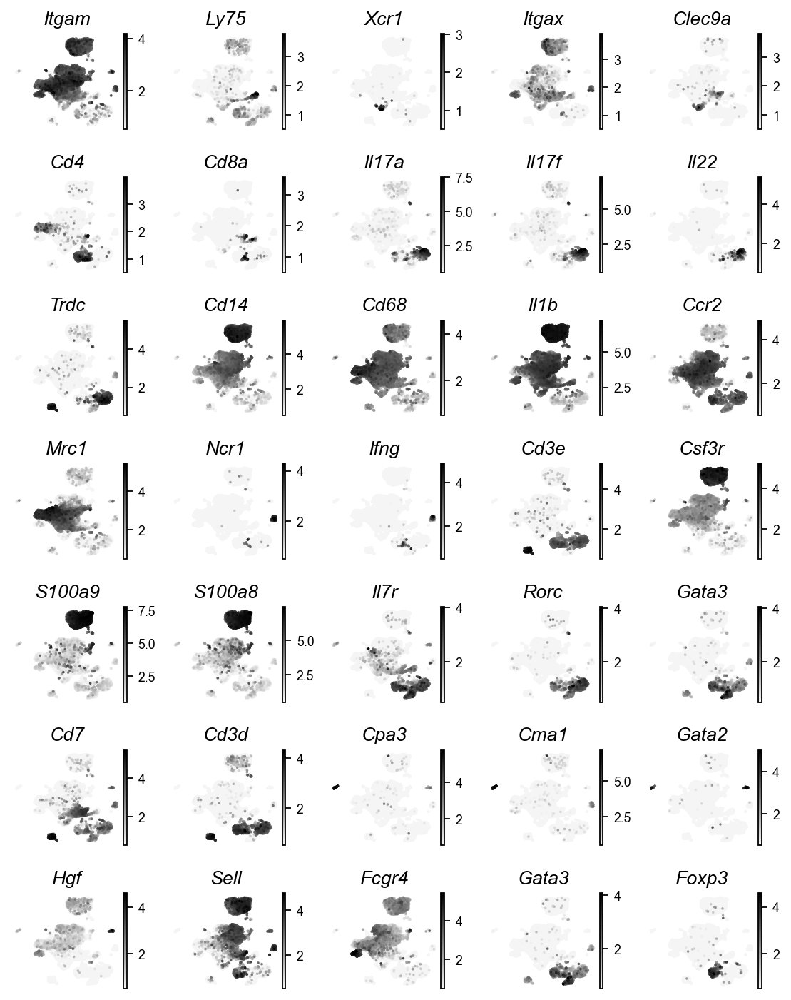

In [8]:
colors = ['whitesmoke', 'black']
n_bins = 100
cmap = LinearSegmentedColormap.from_list('custom_gray', colors, N=n_bins)

# Create figure with 8.5 x 11 inches
fig = plt.figure(figsize=(8.5, 11))

# Create a custom grid layout
gs = fig.add_gridspec(7, 5, hspace=0.5, wspace=0.3)


# Define the layout 
row_layouts = [
    (0, 5),   
    (1, 5),   
    (2, 5),   
    (3, 5),   
    (4, 5),   
    (5, 5),
    (6, 5),
    (7, 5),
    (8, 5),
    (9, 5)
]

plt.rcParams['axes.labelsize'] = 8
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8

# Genes to plot
genes = ['Itgam', 'Ly75', 'Xcr1', 'Itgax', 'Clec9a', 
'Cd4', 'Cd8a', 'Il17a', 'Il17f', 'Il22', 'Trdc', 
'Cd14', 'Cd68', 'Il1b', 'Ccr2', 'Mrc1',
'Ncr1', 'Ifng', 'Cd3e',
'Csf3r', 'S100a9', 'S100a8',
'Il7r', 'Rorc', 'Gata3',
'Cd7', 'Cd3d', 
'Cpa3', 'Cma1', 'Gata2', 'Hgf',
'Sell', 'Fcgr4',
'Gata3', 'Foxp3'

]

plot_idx = 0
for row, num_cols in row_layouts:
    for col in range(num_cols):
        if plot_idx < len(genes):
            # Create subplot at the specified position
            ax = fig.add_subplot(gs[row, col])
            
            # Plot UMAP with gene expression
            sc.pl.umap(adata, color=genes[plot_idx], ax=ax, show=False, 
                    color_map=cmap, vmin=0.5, vmax=None, size=10,
                    na_color='whitesmoke', use_raw=False, frameon=False, legend_loc='right margin')
            
            # Remove spines and axes
            ax.spines['top'].set_visible(False)
            ax.spines['right'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.spines['left'].set_visible(False)
            
            # Remove tick marks and labels
            ax.set_xticks([])
            ax.set_yticks([])
            ax.set_xlabel('')
            ax.set_ylabel('')
            
            # Set italic title
            ax.set_title(f'{genes[plot_idx]}', fontstyle='italic', fontsize=12)
            
            plot_idx += 1

for col in range(5):
    ax = fig.add_subplot(gs[6, col])
    ax.axis('off')

plt.savefig('umaps_genes_of_interest_bulk.svg', dpi=300, bbox_inches='tight')
plt.show()